# SECCIÓN A — Presentación

# **ACTIVIDAD 1: PIPELINE DE MACHINE LEARNING CLÁSICO — PREDICCIÓN DE HELADAS EN LOS ANDES DEL PERÚ**

**Curso:** Ingeniería del Conocimiento (ISO56B) — UNCP, Facultad de Ingeniería de Sistemas
**Semestre:** V (2026-II)
**Fecha:** 19/10/2026

**Integrantes:**
- Echegoyen Rojas Anahi — 2024200183A
- Espinoza Inga Deysi — 2024200184B
- Paucar Ramirez Ariana — 2024200196A
- Tomás Rivera Andriy — 2024200206K

**Dataset elegido:** "Meteorological Data for Frost Prediction in Peru"
**Fuente:** https://www.kaggle.com/datasets/abadpomamaquera/meteorological-data-for-frost-prediction-in-peru/data

**Justificación de la elección:**
- Las heladas son un fenómeno que afecta la agricultura y la ganadería de altura en los Andes peruanos; anticiparlas un día permite proteger cultivos y animales.
- El dataset es público, tiene 1,672,827 registros diarios (2000-2025) de 177 puntos geográficos y 18 variables meteorológicas y geográficas, y cumple los requisitos de la consigna (tabular, más de 500 registros, más de 5 variables, 2 clases).
- Presenta desafíos reales de ciencia de datos: valores faltantes codificados como -999, valores atípicos de precipitación, desbalance de clases y riesgo de fuga de datos.

**Descripción del problema:** Se busca construir un clasificador binario que prediga si **mañana** habrá helada (temperatura mínima ≤ 0 °C) en un punto geográfico, usando las variables meteorológicas de **hoy** (temperaturas, punto de rocío, humedad, viento, humedad del suelo, precipitación y altitud). La variable objetivo `helada_manana` se construye a partir de `temp_min_2m` del día siguiente en el mismo punto. Las heladas representan cerca del 16% de los días, por lo que el problema está desbalanceado e interesa especialmente detectar bien la clase "helada" (un falso negativo significa no avisar de una helada que sí ocurre).

## Configuración del entorno

In [1]:
import os, sys, gc, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

SEMILLA = 42                      # semilla fija para reproducibilidad
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# SECCIÓN B — Carga y Análisis Exploratorio de Datos (EDA)

## B.1 Carga del dataset

In [3]:
# Montar Google Drive para acceder al dataset
from google.colab import drive
drive.mount('/content/drive')

# Ruta al dataset en tu Google Drive (Mi Unidad / datasets / DATASET.csv)
RUTA = "/content/drive/MyDrive/datasets/DATASET.csv"

import os
if not os.path.exists(RUTA):
    raise FileNotFoundError(f"No se encontró el archivo en la ruta especificada: {RUTA}. Asegúrate de que la carpeta 'datasets' y el archivo 'DATASET.csv' existan en tu Google Drive.")

df = pd.read_csv(RUTA)
print("Dataset cargado correctamente desde Google Drive")

Mounted at /content/drive
Dataset cargado correctamente desde Google Drive


## B.2 Primeras filas, shape, tipos de datos y valores nulos

In [4]:
print("Shape (filas, columnas):", df.shape)
display(df.head())
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores nulos (NaN) por columna:")
print(df.isna().sum())

Shape (filas, columnas): (1672827, 18)


,año,dia,temp_2m,punto_rocio_2m,temp_max_2m,temp_min_2m,humedad_rel_2m,viento_2m,viento_max_2m,viento_min_2m,viento_10m,viento_max_10m,viento_min_10m,humedad_suelo,precipitacion,latitud,longitud,altitud
0,2000,1,5.92,1.02,12.86,2.34,73.97,1.60,3.10,0.52,2.01,3.85,0.64,0.32,1.28,-12.6679,-75.3245,4226.68
1,2000,2,5.32,1.42,10.31,2.02,77.91,1.02,2.68,0.14,1.35,3.42,0.18,0.35,2.23,-12.6679,-75.3245,4226.68
2,2000,3,6.15,1.42,12.73,1.79,74.95,1.67,2.88,1.01,2.25,3.67,1.40,0.34,0.52,-12.6679,-75.3245,4226.68
3,2000,4,6.61,1.36,13.41,1.79,72.99,1.66,2.85,0.85,2.27,3.65,1.18,0.32,0.01,-12.6679,-75.3245,4226.68
4,2000,5,5.30,0.39,10.80,1.55,73.31,1.55,2.52,0.53,1.96,3.16,0.67,0.32,0.04,-12.6679,-75.3245,4226.68



Tipos de datos:
año                 int64
dia                 int64
temp_2m           float64
punto_rocio_2m    float64
temp_max_2m       float64
temp_min_2m       float64
humedad_rel_2m    float64
viento_2m         float64
viento_max_2m     float64
viento_min_2m     float64
viento_10m        float64
viento_max_10m    float64
viento_min_10m    float64
humedad_suelo     float64
precipitacion     float64
latitud           float64
longitud          float64
altitud           float64
dtype: object

Valores nulos (NaN) por columna:
año               0
dia               0
temp_2m           0
punto_rocio_2m    0
temp_max_2m       0
temp_min_2m       0
humedad_rel_2m    0
viento_2m         0
viento_max_2m     0
viento_min_2m     0
viento_10m        0
viento_max_10m    0
viento_min_10m    0
humedad_suelo     0
precipitacion     0
latitud           0
longitud          0
altitud           0
dtype: int64


No aparece ningún `NaN`, pero eso **no significa que no haya datos faltantes**: en datos meteorológicos de este tipo el valor **-999** se usa como código de "dato no disponible". Se revisa si existe.

In [5]:
COLS_METEO = [c for c in df.columns if c not in ["año", "dia", "latitud", "longitud", "altitud"]]

conteo_999 = (df[COLS_METEO] == -999).sum()
print("Cantidad de valores -999 por columna:")
print(conteo_999)

# ¿En qué fechas aparecen?
df["fecha"] = pd.to_datetime(df["año"] * 1000 + df["dia"], format="%Y%j")
filas_999 = (df[COLS_METEO] == -999).any(axis=1)
print("\nFilas con -999:", filas_999.sum(), f"({filas_999.mean():.4%} del total)")
print("Fechas donde aparecen:")
print(df.loc[filas_999, "fecha"].value_counts().sort_index())

Cantidad de valores -999 por columna:
temp_2m           531
punto_rocio_2m    531
temp_max_2m       531
temp_min_2m       531
humedad_rel_2m    531
viento_2m         531
viento_max_2m     531
viento_min_2m     531
viento_10m        531
viento_max_10m    531
viento_min_10m    531
humedad_suelo     531
precipitacion     531
dtype: int64

Filas con -999: 531 (0.0317% del total)
Fechas donde aparecen:
fecha
2025-11-13    177
2025-11-14    177
2025-11-15    177
Name: count, dtype: int64


**Hallazgo:** los -999 se concentran en los **últimos días de la serie** (13, 14 y 15 de noviembre de 2025) en todos los puntos geográficos: son días sin dato todavía, no fallos aleatorios. Se convierten a `NaN` para que no se confundan con temperaturas reales (un -999 contaría como "bajo cero" y generaría heladas falsas).

In [6]:
df[COLS_METEO] = df[COLS_METEO].replace(-999, np.nan)
print("Nulos por columna tras convertir -999 a NaN:")
print(df[COLS_METEO].isna().sum())

Nulos por columna tras convertir -999 a NaN:
temp_2m           531
punto_rocio_2m    531
temp_max_2m       531
temp_min_2m       531
humedad_rel_2m    531
viento_2m         531
viento_max_2m     531
viento_min_2m     531
viento_10m        531
viento_max_10m    531
viento_min_10m    531
humedad_suelo     531
precipitacion     531
dtype: int64


## Construcción de la variable objetivo `helada_manana`
Para poder analizar la variable objetivo hay que construirla antes:
1. Ordenar por punto geográfico (`latitud`, `longitud`) y fecha.
2. `helada_hoy` = 1 si `temp_min_2m <= 0 °C` (se mantiene `NaN` donde no hay dato).
3. `helada_manana` = `helada_hoy` del **día siguiente en el mismo punto** (`groupby` + `shift(-1)`).

Se verifica antes que las fechas de cada punto sean consecutivas, para que el `shift` sea correcto.

In [7]:
df = df.sort_values(["latitud", "longitud", "año", "dia"]).reset_index(drop=True)
g = df.groupby(["latitud", "longitud"])

print("Puntos geográficos:", g.ngroups)
print("Filas por punto:", g.size().unique())
saltos = (g["fecha"].diff().dropna() != pd.Timedelta(days=1)).sum()
print("Saltos de fecha (debe ser 0):", saltos)
print("Rango de fechas:", df["fecha"].min().date(), "->", df["fecha"].max().date())

Puntos geográficos: 177
Filas por punto: [9451]
Saltos de fecha (debe ser 0): 0
Rango de fechas: 2000-01-01 -> 2025-11-15


In [8]:
# Helada del día actual (NaN si no hay temperatura mínima)
df["helada_hoy"] = (df["temp_min_2m"] <= 0).astype(float).where(df["temp_min_2m"].notna())

# Helada del día siguiente en el mismo punto geográfico
df["helada_manana"] = df.groupby(["latitud", "longitud"])["helada_hoy"].shift(-1)

print("Filas sin etiqueta (NaN):", df["helada_manana"].isna().sum())

# Dataset para el EDA: solo filas con etiqueta
eda = df.dropna(subset=["helada_manana"]).copy()
eda["helada_manana"] = eda["helada_manana"].astype(int)
print("Filas con etiqueta:", len(eda))

Filas sin etiqueta (NaN): 708
Filas con etiqueta: 1672119


## B.3 Distribución de la variable objetivo

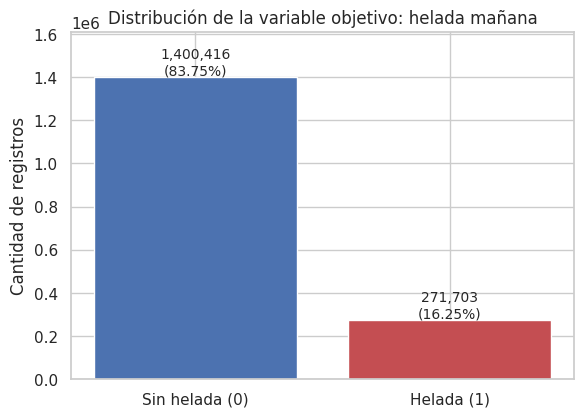

                conteo  porcentaje
helada_manana                     
0              1400416       83.75
1               271703       16.25


In [9]:
conteo = eda["helada_manana"].value_counts().sort_index()
pct = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
barras = ax.bar(["Sin helada (0)", "Helada (1)"], conteo.values, color=["#4c72b0", "#c44e52"])
for b, n, p in zip(barras, conteo.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n:,}\n({p:.2f}%)",
            ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, conteo.max() * 1.15)
ax.set_title("Distribución de la variable objetivo: helada mañana")
ax.set_ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"conteo": conteo, "porcentaje": pct.round(2)}))

## B.4 Estadísticas descriptivas de las variables numéricas

In [10]:
NUM_COLS = ["temp_2m", "temp_max_2m", "temp_min_2m", "punto_rocio_2m", "humedad_rel_2m",
            "viento_2m", "viento_max_2m", "viento_min_2m",
            "viento_10m", "viento_max_10m", "viento_min_10m",
            "humedad_suelo", "precipitacion", "altitud", "dia"]

display(eda[NUM_COLS].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
temp_2m,1672119.0,9.13,3.81,-3.77,6.64,8.41,10.79,30.21
temp_max_2m,1672119.0,16.39,3.77,0.69,13.89,15.82,18.35,36.77
temp_min_2m,1672119.0,3.89,4.36,-10.98,1.15,3.28,6.08,25.03
punto_rocio_2m,1672119.0,1.81,5.73,-31.50,-0.61,2.41,5.08,20.84
humedad_rel_2m,1672119.0,66.91,16.11,4.95,59.15,71.09,78.21,99.74
viento_2m,1672119.0,2.03,0.69,0.01,1.57,2.00,2.44,7.47
viento_max_2m,1672119.0,4.19,1.37,0.02,3.21,4.20,5.14,11.61
viento_min_2m,1672119.0,0.52,0.44,0.00,0.24,0.42,0.67,5.57
viento_10m,1672119.0,2.80,0.87,0.31,2.20,2.75,3.30,10.49
viento_max_10m,1672119.0,5.47,1.65,0.59,4.25,5.48,6.65,15.16


## B.5 Visualizaciones adicionales

### Visualización 1 — Histogramas de variables clave

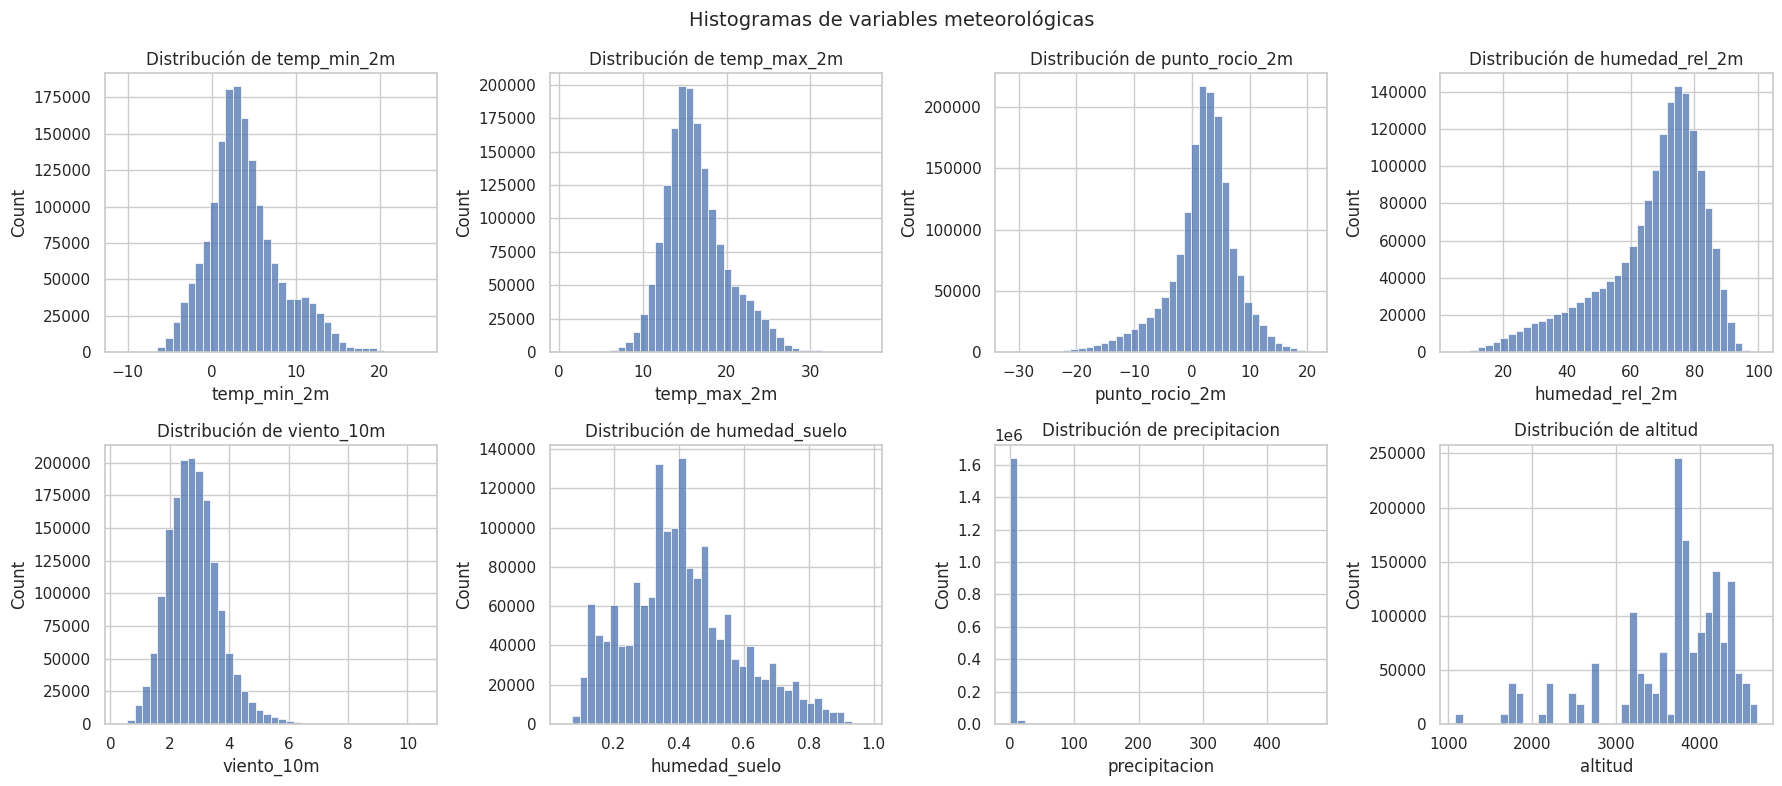

In [11]:
vars_hist = ["temp_min_2m", "temp_max_2m", "punto_rocio_2m", "humedad_rel_2m",
             "viento_10m", "humedad_suelo", "precipitacion", "altitud"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, v in zip(axes.ravel(), vars_hist):
    sns.histplot(eda[v], bins=40, ax=ax, color="#4c72b0")
    ax.set_title(f"Distribución de {v}")
    ax.set_xlabel(v)
plt.suptitle("Histogramas de variables meteorológicas", fontsize=14)
plt.tight_layout()
plt.show()

### Visualización 2 — Boxplots por clase (¿qué variables separan las heladas?)

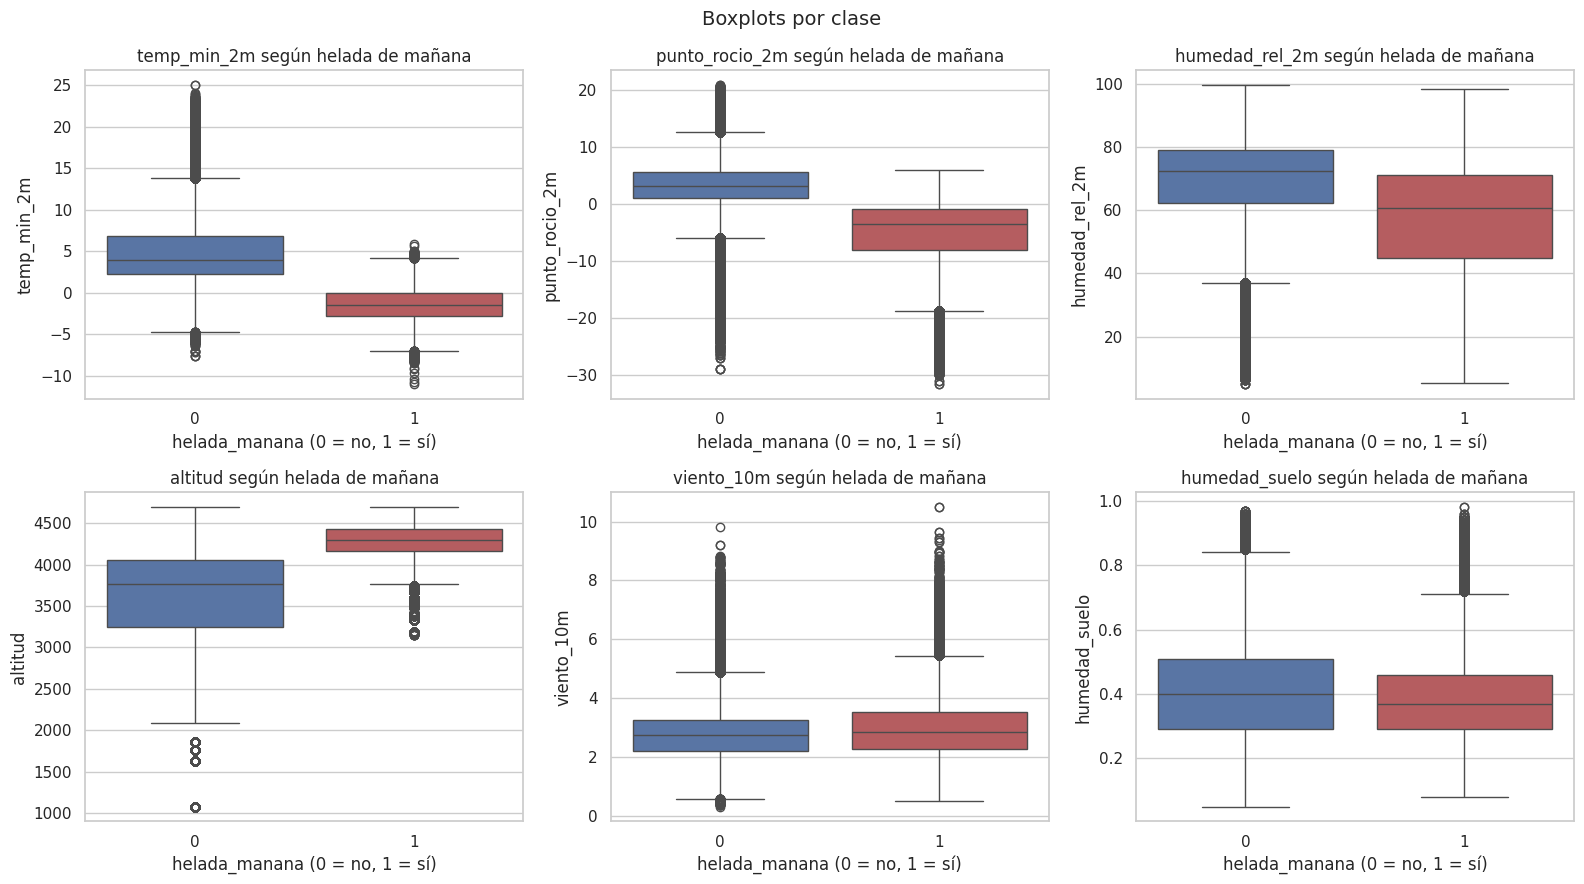

In [12]:
vars_box = ["temp_min_2m", "punto_rocio_2m", "humedad_rel_2m", "altitud", "viento_10m", "humedad_suelo"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, v in zip(axes.ravel(), vars_box):
    sns.boxplot(data=eda, x="helada_manana", y=v, hue="helada_manana", ax=ax,
                palette=["#4c72b0", "#c44e52"], legend=False)
    ax.set_title(f"{v} según helada de mañana")
    ax.set_xlabel("helada_manana (0 = no, 1 = sí)")
plt.suptitle("Boxplots por clase", fontsize=14)
plt.tight_layout()
plt.show()

### Visualización 3 — Valores atípicos en la precipitación

Percentil 99: 15.43 mm
Valores > 50 mm: 1047
Valores > 100 mm: 163
Máximo: 470.24 mm | Asimetría: 28.7


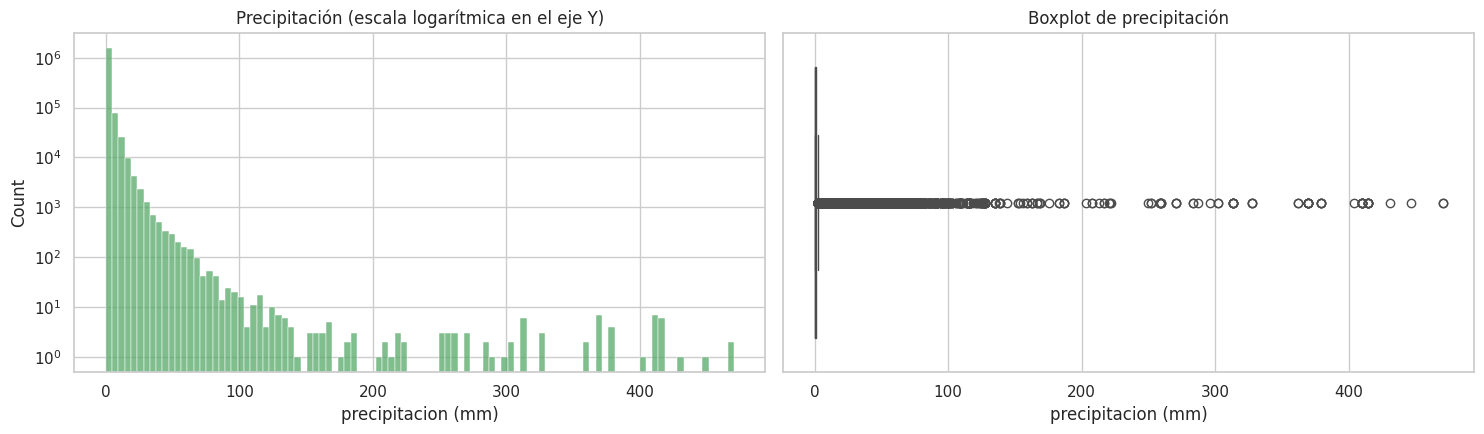

In [13]:
print("Percentil 99:", round(eda["precipitacion"].quantile(0.99), 2), "mm")
print("Valores > 50 mm:", (eda["precipitacion"] > 50).sum())
print("Valores > 100 mm:", (eda["precipitacion"] > 100).sum())
print("Máximo:", eda["precipitacion"].max(), "mm | Asimetría:", round(eda["precipitacion"].skew(), 1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(eda["precipitacion"], bins=100, ax=axes[0], color="#55a868")
axes[0].set_yscale("log")
axes[0].set_title("Precipitación (escala logarítmica en el eje Y)")
axes[0].set_xlabel("precipitacion (mm)")
sns.boxplot(x=eda["precipitacion"], ax=axes[1], color="#55a868")
axes[1].set_title("Boxplot de precipitación")
axes[1].set_xlabel("precipitacion (mm)")
plt.tight_layout()
plt.show()

### Visualización 4 — Matriz de correlación

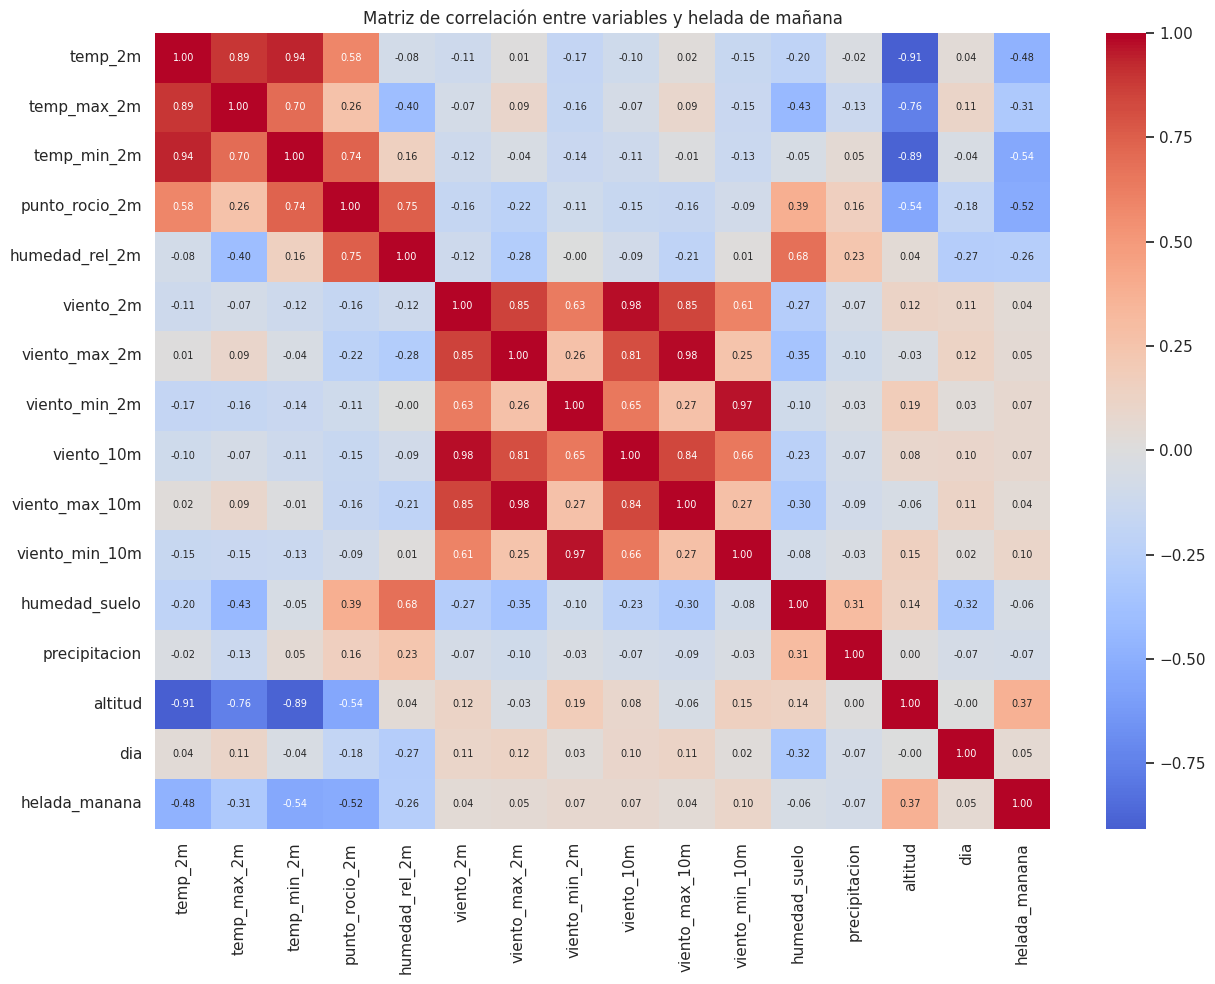

Correlación con la variable objetivo:
temp_min_2m      -0.541
punto_rocio_2m   -0.522
temp_2m          -0.478
temp_max_2m      -0.309
humedad_rel_2m   -0.263
precipitacion    -0.073
humedad_suelo    -0.057
viento_2m         0.041
viento_max_10m    0.045
viento_max_2m     0.051
dia               0.055
viento_min_2m     0.070
viento_10m        0.074
viento_min_10m    0.105
altitud           0.371
Name: helada_manana, dtype: float64

Pares con |r| > 0.9:
('temp_2m', 'temp_min_2m', np.float64(0.937))
('temp_2m', 'altitud', np.float64(0.907))
('viento_2m', 'viento_10m', np.float64(0.976))
('viento_max_2m', 'viento_max_10m', np.float64(0.981))
('viento_min_2m', 'viento_min_10m', np.float64(0.965))


In [14]:
cols_corr = NUM_COLS + ["helada_manana"]
corr = eda[cols_corr].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación entre variables y helada de mañana")
plt.tight_layout()
plt.show()

print("Correlación con la variable objetivo:")
print(corr["helada_manana"].drop("helada_manana").sort_values().round(3))

# Pares de variables muy correlacionadas (|r| > 0.9)
c = corr.drop(index="helada_manana", columns="helada_manana").abs()
pares = [(a, b, round(c.loc[a, b], 3)) for i, a in enumerate(c.columns) for b in c.columns[i + 1:] if c.loc[a, b] > 0.9]
print("\nPares con |r| > 0.9:")
for p in pares:
    print(p)

### Visualización 5 — Tasa de heladas por mes y por altitud, y persistencia

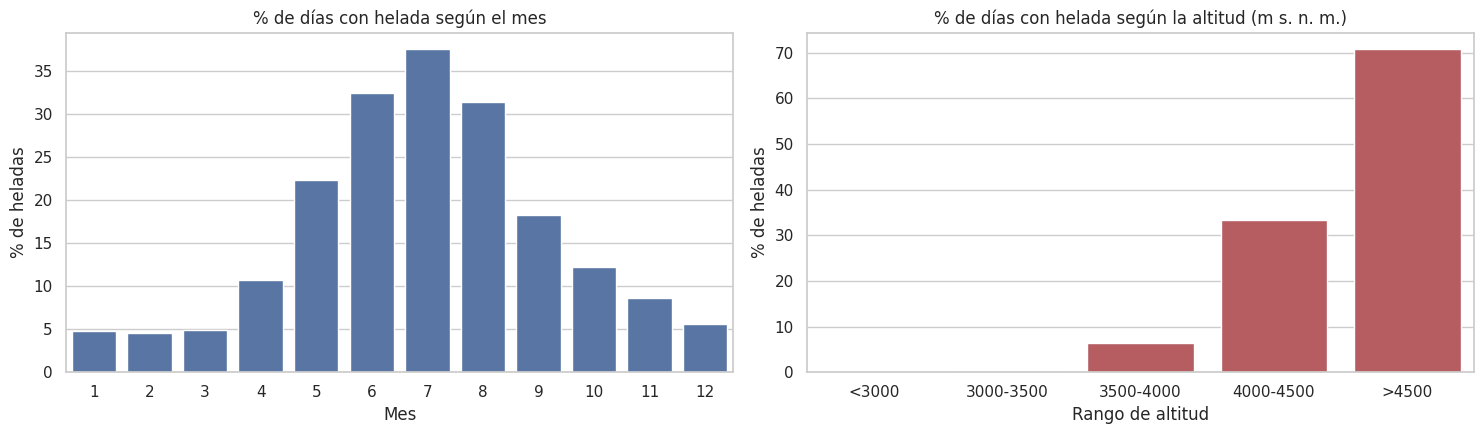

Probabilidad (%) de helada mañana según si hoy hubo helada:
helada_hoy
hoy sin helada     4.71
hoy con helada    75.74
Name: helada_manana, dtype: float64


In [15]:
eda["mes"] = eda["fecha"].dt.month
tasa_mes = eda.groupby("mes")["helada_manana"].mean() * 100

eda["rango_altitud"] = pd.cut(eda["altitud"], bins=[0, 3000, 3500, 4000, 4500, 5000],
                              labels=["<3000", "3000-3500", "3500-4000", "4000-4500", ">4500"])
tasa_alt = eda.groupby("rango_altitud", observed=True)["helada_manana"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(x=tasa_mes.index, y=tasa_mes.values, ax=axes[0], color="#4c72b0")
axes[0].set_title("% de días con helada según el mes")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("% de heladas")
sns.barplot(x=tasa_alt.index, y=tasa_alt.values, ax=axes[1], color="#c44e52")
axes[1].set_title("% de días con helada según la altitud (m s. n. m.)")
axes[1].set_xlabel("Rango de altitud")
axes[1].set_ylabel("% de heladas")
plt.tight_layout()
plt.show()

# Persistencia: ¿si hoy hubo helada, mañana también?
persistencia = eda.dropna(subset=["helada_hoy"]).groupby("helada_hoy")["helada_manana"].mean() * 100
print("Probabilidad (%) de helada mañana según si hoy hubo helada:")
print(persistencia.round(2).rename({0.0: "hoy sin helada", 1.0: "hoy con helada"}))

## B.6 Conclusiones del EDA

El dataset tiene 177 puntos geográficos con datos diarios entre 2000 y 2025, y la variable objetivo está desbalanceada: solo el 16.25% de los días anticipa una helada, por lo que la accuracy será engañosa y habrá que usar F1 macro, recall de la clase helada y ROC, además de un split estratificado. Los datos faltantes venían como -999 (531 filas, 0.03%) y se concentran en los últimos tres días de la serie; no son aleatorios, así que se eliminarán en lugar de imputarse. Las variables que más se relacionan con la helada de mañana son la temperatura mínima de hoy (r ≈ -0.54), el punto de rocío (-0.52), la temperatura media (-0.48) y la altitud (+0.37). La helada es muy estacional y depende de la altitud (≈0% bajo 3,500 m y ≈71% sobre 4,500 m), y además hay persistencia: si hoy hubo helada, mañana la hay con 75.7% de probabilidad frente a 4.7% si hoy no hubo. La precipitación es muy asimétrica (máximo de 470 mm, 163 valores sobre 100 mm); son lluvias extremas reales, por lo que se conservan y se controlará su escala con el escalado. Como preprocesamiento se aplicará: eliminar las filas con nulos, excluir `helada_hoy`, `año`, `latitud` y `longitud` de las variables predictoras, codificar `dia` de forma cíclica (seno y coseno), hacer un split 80/20 estratificado por clase y por bloques de meses (para evitar fuga entre días vecinos) y escalar con StandardScaler ajustado solo con train.

# SECCIÓN C — Preprocesamiento

## C.1 Tratamiento de valores nulos
**Estrategia: eliminar las filas con nulos** (no imputar). Justificación:
- Son 708 filas (0.0423%, aproximadamente 0.04%), así que eliminarlas casi no afecta el tamaño del dataset.
- Los datos faltantes no son aleatorios: corresponden a los últimos 3 días de la serie en todos los puntos (aún sin dato). Imputar significaría **inventar** el clima de esos días.
- Imputar temperatura o humedad con la media distorsionaría justo la relación que queremos aprender, y la etiqueta (helada) se calcula de la temperatura mínima.
- También se eliminan las filas sin etiqueta `helada_manana` (el último día de cada punto y los días anteriores a un dato faltante), porque no se pueden usar para entrenar.

In [16]:
print("Filas antes:", len(df))

hay_nulos = df[COLS_METEO + ["helada_manana"]].isna().any(axis=1)
print("Filas con algún nulo (variables o etiqueta):", hay_nulos.sum(), f"({hay_nulos.mean():.4%})")
print("  - con NaN en variables meteorológicas:", df[COLS_METEO].isna().any(axis=1).sum())
print("  - sin etiqueta helada_manana:", df["helada_manana"].isna().sum())

df_limpio = df.loc[~hay_nulos].copy()
df_limpio["helada_manana"] = df_limpio["helada_manana"].astype(int)

print("\nFilas después:", len(df_limpio))
print("Nulos restantes en variables y etiqueta:", df_limpio[COLS_METEO + ["helada_manana"]].isna().sum().sum())
print("\nDistribución de la etiqueta tras la limpieza:")
print(df_limpio["helada_manana"].value_counts(normalize=True).round(4))

Filas antes: 1672827
Filas con algún nulo (variables o etiqueta): 708 (0.0423%)
  - con NaN en variables meteorológicas: 531
  - sin etiqueta helada_manana: 708

Filas después: 1672119
Nulos restantes en variables y etiqueta: 0

Distribución de la etiqueta tras la limpieza:
helada_manana
0    0.8375
1    0.1625
Name: proportion, dtype: float64


In [17]:
# Liberar memoria: ya no se necesitan el dataset con nulos ni la copia del EDA
del eda, df
gc.collect()
print("Dataset limpio:", df_limpio.shape)

Dataset limpio: (1672119, 21)


## C.2 Codificación de variables y selección de predictoras
**No hay variables categóricas** en este dataset (todas son numéricas), por lo que no se necesita `LabelEncoder`, `OneHotEncoder` ni `get_dummies`.

Lo único parecido a una codificación es la variable `dia` (1-366): es **cíclica** (el día 366 está pegado al día 1), así que se transforma con seno y coseno para que el modelo vea esa continuidad.

**Variables que NO se usan como predictoras:**
- `helada_hoy`: se deriva de `temp_min_2m` y se usa solo como línea base de comparación.
- `año`, `latitud` y `longitud`: con solo 177 puntos fijos el modelo podría memorizar lugares o años en vez de aprender el fenómeno físico.
- `fecha`, `helada_manana`: la primera es auxiliar y la segunda es el objetivo.

In [18]:
df_limpio["dia_sin"] = np.sin(2 * np.pi * df_limpio["dia"] / 366)
df_limpio["dia_cos"] = np.cos(2 * np.pi * df_limpio["dia"] / 366)

FEATURES = ["temp_2m", "temp_max_2m", "temp_min_2m", "punto_rocio_2m", "humedad_rel_2m",
            "viento_2m", "viento_max_2m", "viento_min_2m",
            "viento_10m", "viento_max_10m", "viento_min_10m",
            "humedad_suelo", "precipitacion", "altitud", "dia_sin", "dia_cos"]
TARGET = "helada_manana"
print(len(FEATURES), "variables predictoras")

16 variables predictoras


## C.3 Escalado de variables numéricas
**Elección: `StandardScaler`** (media 0, desviación estándar 1), por estas razones:
- Las variables están en escalas muy distintas (altitud en miles de metros, humedad del suelo entre 0 y 1, viento en pocos m/s). La regresión logística es sensible a la escala (converge mejor y la regularización penaliza por igual a todas las variables); los árboles no lo necesitan.
- La precipitación tiene valores atípicos reales (hasta 470 mm). `MinMaxScaler` comprimiría casi todos los datos en un rango diminuto por culpa de esos extremos, mientras que `StandardScaler` es menos sensible a ellos.

**Importante:** el escalador se ajusta (`fit`) **solo con train** y luego se aplica a test (`transform`), para no filtrar información del test. Por eso se aplica en C.4, justo después del split.

## C.4 Split train/test estratificado
Se trabaja con **todos los registros** (1.67 millones). Para el split se usa `StratifiedGroupKFold` con 5 folds y se toma un fold como test, lo que da un **test ≈ 20%** (equivalente a `test_size=0.2`), **estratificado por la variable objetivo** y con `random_state` fijo.

**¿Por qué por bloques de meses y no un `train_test_split` simple?** Los registros son series diarias: el día de mañana, que es justo la etiqueta, aparece como fila (con su temperatura mínima) del día siguiente. Con un split aleatorio, casi todos los días vecinos de una fila de test caen en train, y los modelos pueden "copiar" la respuesta en vez de predecirla. Para evitarlo cada **año-mes completo** se asigna a train o a test, de modo que ningún mes aparece en ambos. La celda siguiente demuestra la diferencia.

In [19]:
# Grupo = año-mes (cada bloque mensual completo va a train o a test, nunca a ambos)
df_limpio["grupo"] = df_limpio["fecha"].dt.year * 100 + df_limpio["fecha"].dt.month

X = df_limpio[FEATURES]
y = df_limpio[TARGET]
grupos = df_limpio["grupo"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(sgkf.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]

# Escalado: fit solo con train
escalador = StandardScaler()
X_train_sc = escalador.fit_transform(X_train)
X_test_sc = escalador.transform(X_test)

# Helada de "hoy" en las filas de test (para la línea base de la Sección E)
hoy_test = df_limpio["helada_hoy"].iloc[idx_test]

print("Train:", X_train.shape, f"({len(X_train) / len(X):.1%})", "| Test:", X_test.shape, f"({len(X_test) / len(X):.1%})")
print("Media del train escalado (≈0):", X_train_sc.mean().round(4), "| Desv. estándar (≈1):", X_train_sc.std().round(4))

Train: (1338828, 16) (80.1%) | Test: (333291, 16) (19.9%)
Media del train escalado (≈0): 0.0 | Desv. estándar (≈1): 1.0


### Demostración: ¿por qué no un split aleatorio simple?
Se entrena el mismo Árbol de Decisión con (a) un split aleatorio simple estratificado solo por clase y (b) el split por bloques de meses. Si el resultado de (a) es mucho mejor, no es porque el modelo sea mejor: es **fuga de información entre días vecinos**.

In [20]:
def metricas_rapidas(modelo, Xa, ya, Xb, yb):
    modelo.fit(Xa, ya)
    p = modelo.predict(Xb)
    return {"Accuracy": accuracy_score(yb, p), "Recall (helada)": recall_score(yb, p),
            "F1 macro": f1_score(yb, p, average="macro")}

X_a, X_b, y_a, y_b = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
demo_split = pd.DataFrame({
    "Split aleatorio simple": metricas_rapidas(DecisionTreeClassifier(random_state=SEMILLA), X_a, y_a, X_b, y_b),
    "Split por bloques de meses": metricas_rapidas(DecisionTreeClassifier(random_state=SEMILLA), X_train, y_train, X_test, y_test),
}).T
display(demo_split.round(4))
del X_a, X_b, y_a, y_b, X     # liberar memoria
gc.collect()

,Accuracy,Recall (helada),F1 macro
Split aleatorio simple,0.9770,0.9288,0.9577
Split por bloques de meses,0.9085,0.7437,0.8433


28

## C.5 Verificación de la distribución de clases

In [21]:
dist = pd.DataFrame({
    "Dataset completo (%)": y.value_counts(normalize=True) * 100,
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100,
}).round(2)
dist.index = ["Sin helada (0)", "Helada (1)"]
display(dist)
print("Registros en train:", y_train.value_counts().to_dict(), "| en test:", y_test.value_counts().to_dict())

meses_train = set(grupos.iloc[idx_train])
meses_test = set(grupos.iloc[idx_test])
print("Meses en train:", len(meses_train), "| meses en test:", len(meses_test),
      "| meses compartidos (debe ser 0):", len(meses_train & meses_test))

,Dataset completo (%),Train (%),Test (%)
Sin helada (0),83.75,84.11,82.29
Helada (1),16.25,15.89,17.71


Registros en train: {0: 1126140, 1: 212688} | en test: {0: 274276, 1: 59015}
Meses en train: 249 | meses en test: 62 | meses compartidos (debe ser 0): 0


# SECCIÓN D — Modelado
Se entrenan **4 modelos distintos** con el dataset completo (1.34 millones de registros de entrenamiento): Regresión Logística, Árbol de Decisión, Random Forest y Gradient Boosting (`HistGradientBoostingClassifier`). Cada uno se entrena con el train escalado y se evalúa sobre el test. La optimización de hiperparámetros se hace después, sobre el mejor modelo (Sección F).

**Nota sobre el tamaño de los datos:** el SVM con kernel RBF y KNN **no son viables** con más de un millón de registros (su costo crece con el cuadrado del número de muestras o requieren comparar cada predicción contra todo el train), por lo que se reemplazan por Gradient Boosting, que sí escala. En el Random Forest se limitan la profundidad efectiva (`min_samples_leaf=20`) y el tamaño de la muestra por árbol (`max_samples=0.2`) para que entrene en un tiempo razonable y sin agotar la memoria.

In [22]:
NOMBRES_CLASES = ["Sin helada", "Helada"]

modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=SEMILLA),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, max_samples=0.2,
                                            random_state=SEMILLA, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEMILLA),
}

def puntaje(modelo, X):
    """Puntaje de la clase 'helada': probabilidad si el modelo la da; si no, distancia al hiperplano.
    Sirve para calcular el AUC y dibujar la curva ROC."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

resultados = {}      # métricas por modelo
predicciones = {}    # predicciones sobre test
puntajes = {}        # puntajes para la curva ROC

for nombre, modelo in modelos.items():
    t0 = time.time()
    modelo.fit(X_train_sc, y_train)                 # entrenar con train
    t_entreno = time.time() - t0

    y_pred = modelo.predict(X_test_sc)              # predecir sobre test
    y_score = puntaje(modelo, X_test_sc)

    predicciones[nombre] = y_pred
    puntajes[nombre] = y_score
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (helada)": precision_score(y_test, y_pred),
        "Recall (helada)": recall_score(y_test, y_pred),
        "F1 (helada)": f1_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "AUC": roc_auc_score(y_test, y_score),
        "Tiempo de entrenamiento (s)": t_entreno,
    }

    print("=" * 60)
    print(nombre)
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=NOMBRES_CLASES, digits=3))

Regresión Logística
              precision    recall  f1-score   support

  Sin helada      0.950     0.971     0.961    274276
      Helada      0.851     0.764     0.805     59015

    accuracy                          0.934    333291
   macro avg      0.900     0.867     0.883    333291
weighted avg      0.933     0.934     0.933    333291

Árbol de Decisión
              precision    recall  f1-score   support

  Sin helada      0.945     0.944     0.944    274276
      Helada      0.741     0.744     0.742     59015

    accuracy                          0.908    333291
   macro avg      0.843     0.844     0.843    333291
weighted avg      0.909     0.908     0.909    333291

Random Forest
              precision    recall  f1-score   support

  Sin helada      0.951     0.972     0.961    274276
      Helada      0.856     0.767     0.809     59015

    accuracy                          0.936    333291
   macro avg      0.903     0.870     0.885    333291
weighted avg      0.93

### Matrices de confusión (heatmap) de cada modelo

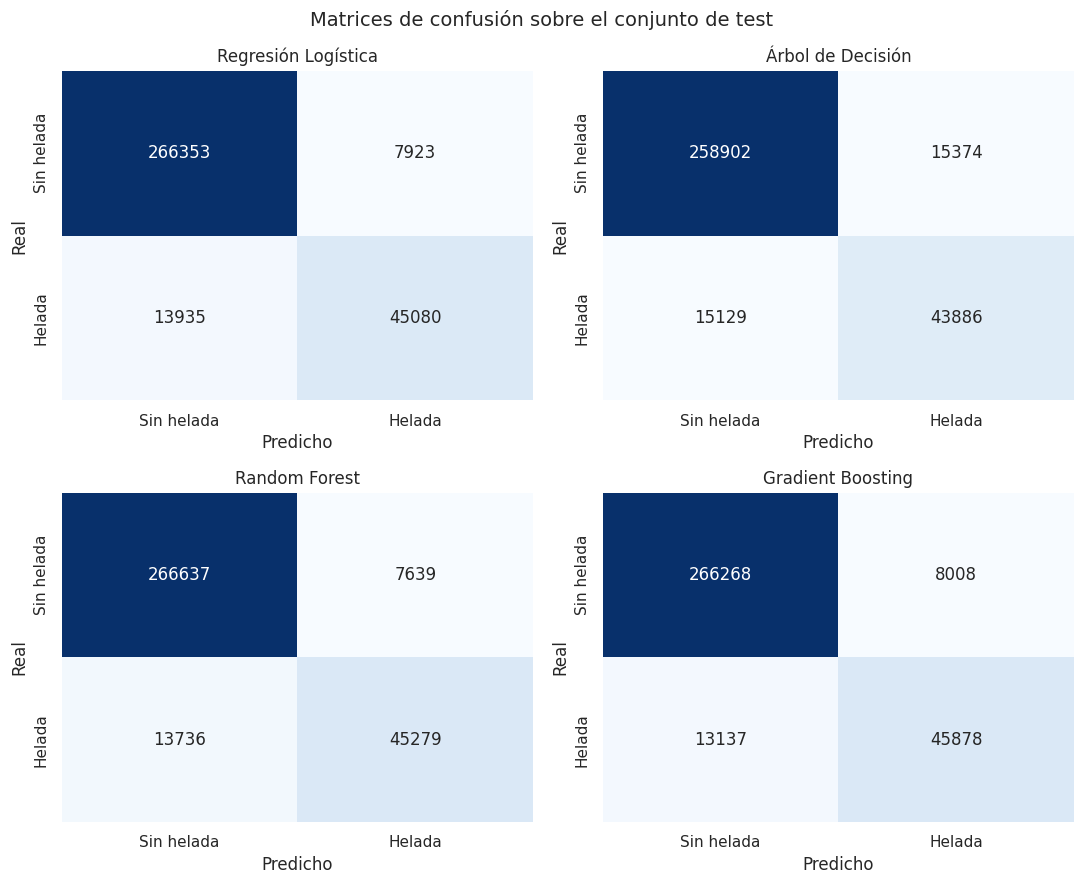

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (nombre, y_pred) in zip(axes.ravel(), predicciones.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES, ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
plt.suptitle("Matrices de confusión sobre el conjunto de test", fontsize=14)
plt.tight_layout()
plt.show()

# SECCIÓN E — Evaluación Comparativa
Además de los 4 modelos se incluye una **línea base de persistencia**: "si hoy hubo helada, mañana también". Es una regla sin aprendizaje; si un modelo no la supera, no está aportando valor.

## E.1 Tabla resumen

In [24]:
LINEA_BASE = "Línea base (helada hoy → mañana)"
y_base = hoy_test.astype(int)
resultados[LINEA_BASE] = {
    "Accuracy": accuracy_score(y_test, y_base),
    "Precision (helada)": precision_score(y_test, y_base),
    "Recall (helada)": recall_score(y_test, y_base),
    "F1 (helada)": f1_score(y_test, y_base),
    "F1 macro": f1_score(y_test, y_base, average="macro"),
    "AUC": roc_auc_score(y_test, y_base),
    "Tiempo de entrenamiento (s)": np.nan,
}

tabla = pd.DataFrame(resultados).T.sort_values("F1 macro", ascending=False)
display(tabla.round(4))

,Accuracy,Precision (helada),Recall (helada),F1 (helada),F1 macro,AUC,Tiempo de entrenamiento (s)
Gradient Boosting,0.9366,0.8514,0.7774,0.8127,0.8873,0.9758,24.7028
Random Forest,0.9359,0.8556,0.7672,0.8090,0.8852,0.9758,119.5249
Regresión Logística,0.9344,0.8505,0.7639,0.8049,0.8827,0.9727,10.5683
Línea base (helada hoy → mañana),0.9178,0.7685,0.7667,0.7676,0.8588,0.8585,NaN
Árbol de Decisión,0.9085,0.7406,0.7436,0.7421,0.8432,0.8438,27.4614


## E.2 Gráfico de barras comparativo

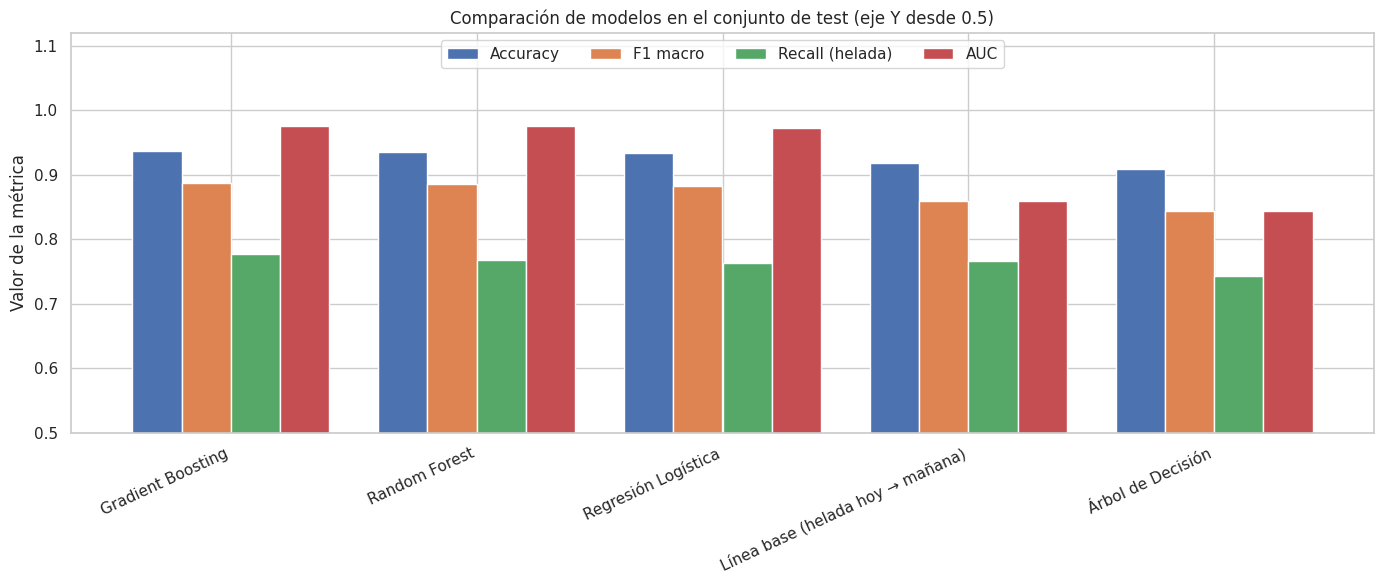

In [25]:
metricas_graf = ["Accuracy", "F1 macro", "Recall (helada)", "AUC"]
ax = tabla[metricas_graf].plot(kind="bar", figsize=(14, 6), width=0.8, edgecolor="white")
ax.set_ylim(0.5, 1.12)
ax.set_title("Comparación de modelos en el conjunto de test (eje Y desde 0.5)")
ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="upper center", ncol=4)
plt.tight_layout()
plt.show()

## E.3 Curvas ROC

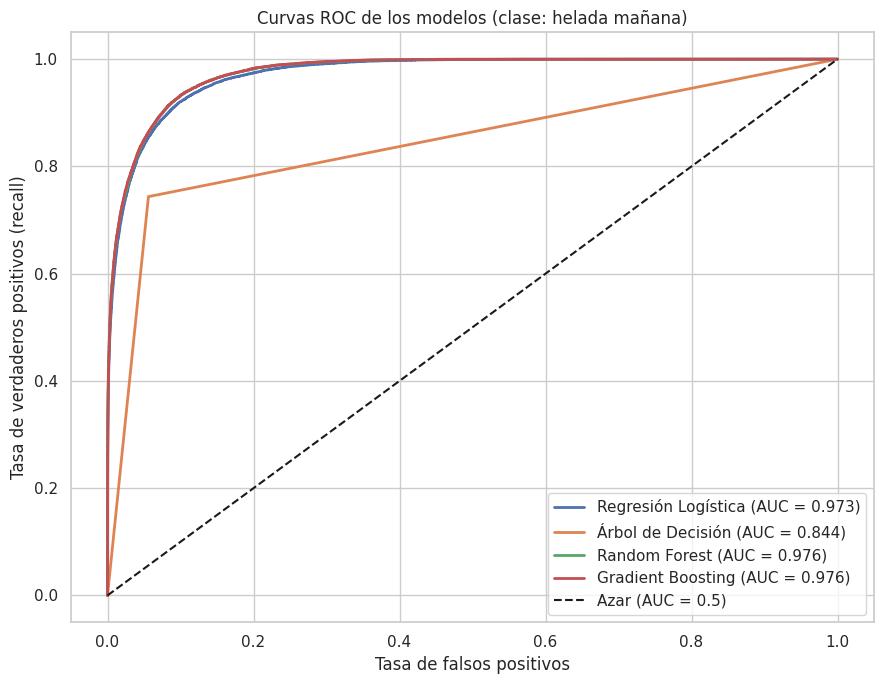

In [28]:
plt.figure(figsize=(9, 7))
for nombre, y_score in puntajes.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)
    plt.plot(fpr, tpr, linewidth=2, label=f"{nombre} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curvas ROC de los modelos (clase: helada mañana)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## E.4 Análisis de resultados

El mejor modelo fue **Gradient Boosting**: obtuvo el mayor F1 macro (0.8873), recall de la clase helada (0.7774) y AUC (0.9758), con un entrenamiento de 24.7 s. Random Forest quedó cerca (F1 macro 0.8852, AUC 0.9758; 119.5 s), al igual que la Regresión Logística (F1 macro 0.8827, AUC 0.9727; 10.6 s), que fue mucho más rápida y fácil de interpretar. El Árbol de Decisión fue el de menor rendimiento (F1 macro 0.8432, AUC 0.8438); además, en la demostración de la Sección C.4 su F1 macro pasó de 0.9577 con un split aleatorio simple a 0.8433 con el split por bloques, lo que evidencia fuga de información entre días vecinos. La **accuracy es engañosa**: un modelo que siempre dijera "no habrá helada" acertaría el 83.75% de los días, por eso se usan F1 macro, recall y AUC. La **línea base de persistencia** ("si hoy hubo helada, mañana también") logra accuracy 0.9178, F1 macro 0.8588, recall 0.7667, precisión 0.7685 y AUC 0.8585. Los modelos la superan claramente en precisión y AUC, pero el mejor recall (0.7774) solo mejora ligeramente la línea base: con el umbral de 0.5 todavía se dejan pasar más de una de cada cinco heladas. Esa diferencia entre precisión y recall se analiza en la Sección F.


# SECCIÓN F — Modelo Final y Serialización
## F.1 Selección del mejor modelo y búsqueda de hiperparámetros
Se elige automáticamente el modelo con mayor **F1 macro** de la tabla (excluyendo la línea base) y se optimiza con `GridSearchCV` (validación cruzada estratificada de 3 folds **por bloques de meses**, sobre train, `scoring="f1_macro"`).

El modelo final es un **`Pipeline` (escalador + modelo)**: así el escalado va dentro de la validación cruzada (sin fuga de datos) y, al serializarlo, el modelo guardado recibe datos **sin escalar**.

In [27]:
param_grids = {
    "Regresión Logística": {"modelo__C": [0.01, 0.1, 1, 10, 100],
                            "modelo__class_weight": [None, "balanced"]},
    "Árbol de Decisión": {"modelo__max_depth": [6, 10, 14],
                          "modelo__min_samples_leaf": [50, 500]},
    "Random Forest": {"modelo__max_depth": [12, 20],
                      "modelo__min_samples_leaf": [20, 100]},
    "Gradient Boosting": {"modelo__max_iter": [100, 200],
                          "modelo__learning_rate": [0.05, 0.1],
                          "modelo__max_leaf_nodes": [31, 63]},
}

mejor_nombre = tabla.drop(index=LINEA_BASE)["F1 macro"].idxmax()
print("Mejor modelo según F1 macro:", mejor_nombre)

pipe = Pipeline([("escalador", StandardScaler()),
                 ("modelo", clone(modelos[mejor_nombre]))])

# Liberar memoria: ya no se necesitan los modelos ya ajustados ni los datos escalados
modelos.clear()
del X_train_sc, X_test_sc
gc.collect()

busqueda = GridSearchCV(
    pipe, param_grids[mejor_nombre],
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA),
    scoring="f1_macro", n_jobs=1, verbose=1)

# groups: cada año-mes completo queda en un solo fold (sin fuga entre días vecinos)
busqueda.fit(X_train, y_train, groups=grupos_train)

print("\nMejores hiperparámetros:", busqueda.best_params_)
print("Mejor F1 macro en validación cruzada:", round(busqueda.best_score_, 4))

res_cv = pd.DataFrame(busqueda.cv_results_).sort_values("rank_test_score")
cols = ["rank_test_score", "mean_test_score", "std_test_score"] + [c for c in res_cv.columns if c.startswith("param_")]
display(res_cv[cols].head(8).round(4))

modelo_final = busqueda.best_estimator_

Mejor modelo según F1 macro: Gradient Boosting
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Mejores hiperparámetros: {'modelo__learning_rate': 0.05, 'modelo__max_iter': 200, 'modelo__max_leaf_nodes': 63}
Mejor F1 macro en validación cruzada: 0.8846


,rank_test_score,mean_test_score,std_test_score,param_modelo__learning_rate,param_modelo__max_iter,param_modelo__max_leaf_nodes
3,1,0.8846,0.0021,0.05,200,63
1,2,0.8837,0.0026,0.05,100,63
2,3,0.8835,0.0028,0.05,200,31
5,4,0.8834,0.0025,0.10,100,63
7,4,0.8834,0.0025,0.10,200,63
4,6,0.8824,0.0025,0.10,100,31
6,6,0.8824,0.0025,0.10,200,31
0,8,0.8821,0.0027,0.05,100,31


## F.2 Evaluación del modelo optimizado sobre test

              precision    recall  f1-score   support

  Sin helada      0.953     0.972     0.963    274276
      Helada      0.856     0.779     0.816     59015

    accuracy                          0.938    333291
   macro avg      0.905     0.875     0.889    333291
weighted avg      0.936     0.938     0.937    333291



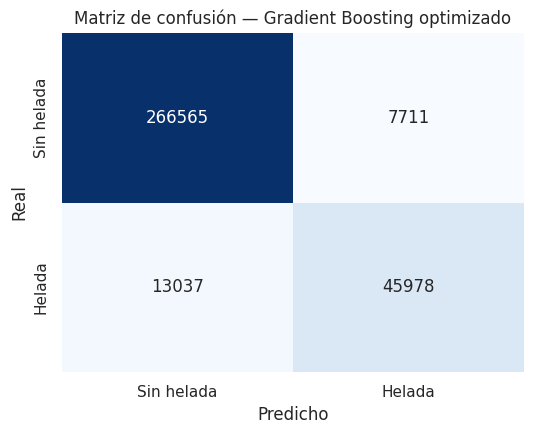

,Por defecto,Optimizado
Accuracy,0.9366,0.9377
Precision (helada),0.8514,0.8564
Recall (helada),0.7774,0.7791
F1 (helada),0.8127,0.8159
F1 macro,0.8873,0.8892
AUC,0.9758,0.9769


In [29]:
y_pred_final = modelo_final.predict(X_test)
y_score_final = puntaje(modelo_final, X_test)

print(classification_report(y_test, y_pred_final, target_names=NOMBRES_CLASES, digits=3))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES)
plt.title(f"Matriz de confusión — {mejor_nombre} optimizado")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

comparacion = pd.DataFrame({
    "Por defecto": resultados[mejor_nombre],
    "Optimizado": {
        "Accuracy": accuracy_score(y_test, y_pred_final),
        "Precision (helada)": precision_score(y_test, y_pred_final),
        "Recall (helada)": recall_score(y_test, y_pred_final),
        "F1 (helada)": f1_score(y_test, y_pred_final),
        "F1 macro": f1_score(y_test, y_pred_final, average="macro"),
        "AUC": roc_auc_score(y_test, y_score_final),
    }
}).drop(index="Tiempo de entrenamiento (s)")
display(comparacion.round(4))

### Compromiso entre precisión y recall
En este problema un **falso negativo** (no avisar de una helada que sí ocurre) es más costoso que un falso positivo (avisar de una helada que no ocurre). Se compara el modelo optimizado con una variante que da más peso a la clase minoritaria (`class_weight="balanced"`).

In [30]:
if "class_weight" in modelo_final.named_steps["modelo"].get_params():
    alt = clone(modelo_final).set_params(modelo__class_weight="balanced")
    alt.fit(X_train, y_train)
    p_alt = alt.predict(X_test)
    trade = pd.DataFrame({
        "Optimizado": comparacion["Optimizado"],
        'Con class_weight="balanced"': {
            "Accuracy": accuracy_score(y_test, p_alt),
            "Precision (helada)": precision_score(y_test, p_alt),
            "Recall (helada)": recall_score(y_test, p_alt),
            "F1 (helada)": f1_score(y_test, p_alt),
            "F1 macro": f1_score(y_test, p_alt, average="macro"),
            "AUC": roc_auc_score(y_test, puntaje(alt, X_test)),
        }
    })
    display(trade.round(4))
    print("Heladas no detectadas (falsos negativos):",
          "optimizado =", confusion_matrix(y_test, y_pred_final)[1, 0],
          "| balanced =", confusion_matrix(y_test, p_alt)[1, 0])
else:
    print("Este modelo no tiene el parámetro class_weight; se omite la comparación.")

,Optimizado,"Con class_weight=""balanced"""
Accuracy,0.9377,0.9086
Precision (helada),0.8564,0.6746
Recall (helada),0.7791,0.9342
F1 (helada),0.8159,0.7835
F1 macro,0.8892,0.8628
AUC,0.9769,0.9772


Heladas no detectadas (falsos negativos): optimizado = 13037 | balanced = 3881


## F.3 Serialización con `joblib.dump()`

In [31]:
RUTA_MODELO = "modelo_heladas_final.joblib"
joblib.dump(modelo_final, RUTA_MODELO)
print("Modelo guardado en:", RUTA_MODELO, "| tamaño:", round(os.path.getsize(RUTA_MODELO) / 1024, 1), "KB")

Modelo guardado en: modelo_heladas_final.joblib | tamaño: 1133.5 KB


## F.4 Carga con `joblib.load()` y predicción sobre datos nuevos
Como datos nuevos se usan **registros reales de meses que el modelo nunca vio** (el conjunto de test, que no participó ni en el entrenamiento ni en la búsqueda de hiperparámetros).

In [32]:
modelo_cargado = joblib.load(RUTA_MODELO)
print("Modelo cargado:", type(modelo_cargado).__name__)

# El modelo cargado debe dar exactamente las mismas predicciones que el original
print("Predicciones idénticas al modelo en memoria:",
      np.array_equal(modelo_final.predict(X_test), modelo_cargado.predict(X_test)))

# 1) Diez registros nuevos (nunca vistos), con su etiqueta real
nuevos = df_limpio.loc[X_test.sample(10, random_state=SEMILLA).index]
pred_nuevos = modelo_cargado.predict(nuevos[FEATURES])      # datos sin escalar: el Pipeline escala solo

demo = pd.DataFrame({
    "fecha": nuevos["fecha"].dt.date.values,
    "altitud": nuevos["altitud"].values,
    "temp_min_hoy": nuevos["temp_min_2m"].values,
    "helada real mañana": nuevos[TARGET].values,
    "helada predicha": pred_nuevos,
    "puntaje": puntaje(modelo_cargado, nuevos[FEATURES]).round(3),
})
display(demo)

# 2) Evaluación del modelo cargado sobre todos los registros nuevos (test)
p_c = modelo_cargado.predict(X_test)
s_c = puntaje(modelo_cargado, X_test)
print(f"\nEvaluación del modelo cargado sobre {len(X_test):,} registros nunca vistos:")
print("Accuracy:", round(accuracy_score(y_test, p_c), 4),
      "| Recall helada:", round(recall_score(y_test, p_c), 4),
      "| F1 macro:", round(f1_score(y_test, p_c, average="macro"), 4),
      "| AUC:", round(roc_auc_score(y_test, s_c), 4))

Modelo cargado: Pipeline
Predicciones idénticas al modelo en memoria: True


,fecha,altitud,temp_min_hoy,helada real mañana,helada predicha,puntaje
0,2018-11-29,3766.49,4.32,0,0,0.000
1,2000-02-02,2476.42,11.49,0,0,0.000
2,2023-03-14,3766.49,3.55,0,0,0.002
3,2023-03-24,1854.11,13.26,0,0,0.000
4,2000-04-15,3843.55,3.36,0,0,0.003
5,2015-08-07,3769.58,0.85,1,0,0.085
6,2016-06-16,4219.42,0.41,1,1,0.679
7,2014-09-26,4219.42,0.37,1,0,0.176
8,2004-03-28,3739.76,3.10,0,0,0.003
9,2001-12-31,4043.81,0.44,0,0,0.062



Evaluación del modelo cargado sobre 333,291 registros nunca vistos:
Accuracy: 0.9377 | Recall helada: 0.7791 | F1 macro: 0.8892 | AUC: 0.9769


# SECCIÓN G — Conclusiones

### G.1 Resumen de resultados
Se construyó un clasificador que predice si **mañana** habrá helada en un punto de los Andes peruanos a partir de las variables meteorológicas de hoy, trabajando con el **dataset completo**. Con un split 80/20 estratificado por bloques de meses se compararon 4 modelos y una línea base de persistencia: el mejor fue Gradient Boosting (F1 macro 0.8873, AUC 0.9758), seguido de cerca por Random Forest y Regresión Logística. La búsqueda con `GridSearchCV` (tasa de aprendizaje 0.05, 200 iteraciones y 63 hojas) lo llevó a F1 macro 0.8892, AUC 0.9769, accuracy 0.9377, precisión 0.8564 y recall de heladas 0.7791, una mejora pequeña frente a los parámetros por defecto. Al dar más peso a la clase helada (`class_weight="balanced"`), el recall subió a 0.9342 y los falsos negativos bajaron de 13,037 a 3,881 (sobre 59,015 heladas en test), a costa de bajar la precisión a 0.6746 y la accuracy a 0.9086. El modelo final se serializó con `joblib` como `Pipeline` (escalador + modelo, 1133.5 KB) y el modelo cargado reproduce exactamente las mismas predicciones sobre los 333,291 registros de test.

### G.2 Lecciones aprendidas
- Un dataset "sin nulos" puede tener datos faltantes escondidos: aquí los -999 correspondían a los últimos 3 días de la serie en todos los puntos, y convertirlos a `NaN` evitó heladas falsas.
- Hay que cuidar la **fuga de datos** en dos niveles. Primero, la temperatura mínima define la etiqueta y se puede reconstruir casi exacta con la media y la máxima del mismo día (correlación 0.98), por eso se planteó la predicción a un día y la etiqueta se construyó con `groupby` + `shift(-1)`. Segundo, con el dataset completo un split aleatorio simple deja los días vecinos de cada registro de test en train: el Árbol de Decisión parecía excelente (F1 macro 0.9577) y, al dividir por bloques de meses, bajó a 0.8433.
- La accuracy es engañosa con clases desbalanceadas (83.75% / 16.25%); conviene mirar recall, F1 macro y AUC, y compararse con una **línea base simple**. Aquí el recall del mejor modelo apenas supera al de persistencia (0.7791 frente a 0.7667).
- Con más de un millón de registros el costo computacional pasa a ser un criterio de diseño: el SVM con kernel RBF y KNN no son viables, y el Random Forest hubo que limitarlo (`min_samples_leaf`, `max_samples`).
- Un modelo más complejo no es necesariamente mucho mejor: la Regresión Logística quedó a unas 0.004 de F1 macro del mejor, en una fracción del tiempo.
- Escalar dentro de un `Pipeline` evita filtrar información del test y permite guardar un modelo que acepta datos sin escalar.

### G.3 Limitaciones
- No se confirmó si los datos provienen de reanálisis, satélite o estaciones físicas; por ello, podrían no reflejar condiciones locales exactas.
- Aunque el split por bloques de meses evita la fuga entre días vecinos, los meses de test están intercalados en el mismo periodo (2000-2025) que los de train y los mismos 177 puntos aparecen en ambos conjuntos; no equivale a pronosticar el futuro ni a predecir en lugares nuevos.
- La etiqueta depende de un umbral fijo (≤ 0 °C) calculado del mismo dataset; no se validó contra reportes reales de heladas.
- Con el umbral por defecto el modelo deja pasar cerca de una de cada cinco heladas (recall 0.7774); mejorar el recall implica aceptar más falsas alarmas.
- Hay alta colinealidad entre variables (viento a 2 y 10 m, temperatura y altitud), el horizonte es de solo un día y la búsqueda de hiperparámetros fue acotada (8 combinaciones, 3 folds).

### G.4 Posibles mejoras futuras
- Evaluar con un **split temporal** (entrenar con los primeros años y probar con los últimos) y validación cruzada **por punto geográfico**.
- Añadir variables de días anteriores (rezagos y tendencias de temperatura mínima, humedad y punto de rocío) y probar horizontes de más de un día.
- Ampliar la búsqueda de hiperparámetros (`RandomizedSearchCV`) y probar librerías como LightGBM o XGBoost.
- Ajustar el **umbral de decisión** con la curva precisión-recall o usar costos asimétricos, y calibrar las probabilidades.
- Validar con datos de estaciones (por ejemplo, SENAMHI) y desplegar el modelo como un sistema de alerta temprana.
